In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('titanic.csv')


In [3]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

data_for_analysis = df[[target] + features]


In [4]:
print(data_for_analysis.info())
print(data_for_analysis.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Age       891 non-null    float64
 3   Sex       891 non-null    int64  
 4   Fare      891 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 48.9 KB
None
Survived    0
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64


In [5]:
corr_matrix = data_for_analysis.corr(method='pearson').round(2)
print(corr_matrix)

survived_corr = corr_matrix['Survived'].drop('Survived')
most_positive = survived_corr.idxmax()
most_negative = survived_corr.idxmin()

print(f"Наиболее сильная положительная корреляция: {most_positive} ({survived_corr[most_positive]})")
print(f"Наиболее сильная отрицательная корреляция: {most_negative} ({survived_corr[most_negative]})")


          Survived  Pclass   Age   Sex  Fare  SibSp  Parch
Survived      1.00   -0.34 -0.06  0.54  0.26  -0.04   0.08
Pclass       -0.34    1.00 -0.34 -0.13 -0.55   0.08   0.02
Age          -0.06   -0.34  1.00 -0.08  0.10  -0.23  -0.17
Sex           0.54   -0.13 -0.08  1.00  0.18   0.11   0.25
Fare          0.26   -0.55  0.10  0.18  1.00   0.16   0.22
SibSp        -0.04    0.08 -0.23  0.11  0.16   1.00   0.41
Parch         0.08    0.02 -0.17  0.25  0.22   0.41   1.00
Наиболее сильная положительная корреляция: Sex (0.54)
Наиболее сильная отрицательная корреляция: Pclass (-0.34)


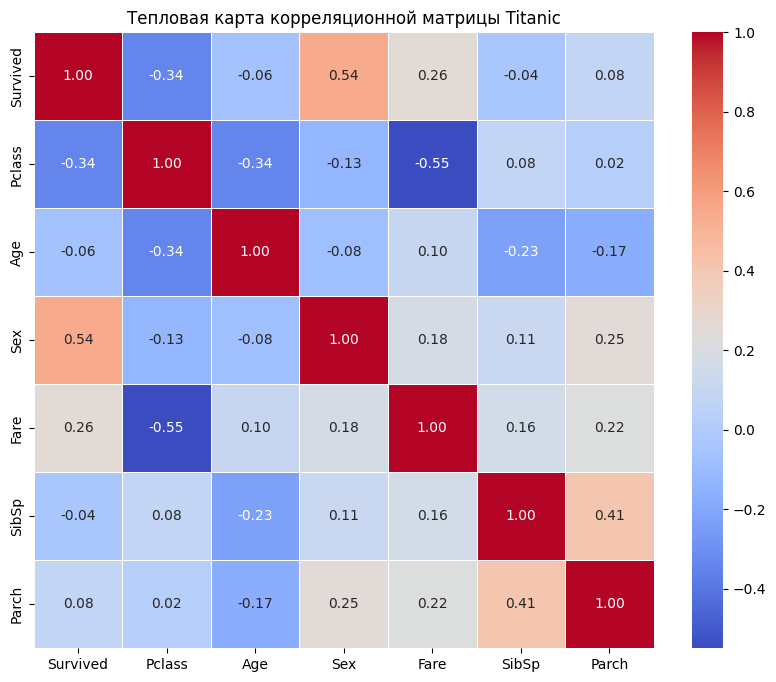

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Тепловая карта корреляционной матрицы Titanic')
plt.show()
